
# Evaluating and Optimizing a Customer Support Chatbot

## Project Overview

This project evaluates the performance of an existing
open-source Python chatbot and investigates whether
additional NLP training examples improve its accuracy.

The original chatbot is based on Patrick Loeber's
PyTorch chatbot:
https://github.com/patrickloeber/pytorch-chatbot

## Experiment Design

Two chatbot models are compared:

- Baseline chatbot: 26 training questions
- Optimized chatbot: 61 training questions

Both models recognize seven customer intent categories.

The experiment uses:
- 35 manually labelled development questions
- 85 synthetic final test questions
- 10 simulated two-turn customer conversations
- A confidence threshold of 0.75 for final evaluation

## Evaluation Methods

The project evaluates intent accuracy, precision,
recall, F1-score, confusion matrices, fallback rates,
local processing time and simulated session success.

## Data and Limitations

All evaluation questions were manually constructed.
The interaction logs were generated by replaying
synthetic questions through the trained chatbots.

The project does not measure actual customer purchases,
CSAT, NPS or customer lifetime value.

The training process was not seeded, so retraining may
produce different results.



## Experimental Methodology

### 1. Research Approach

This project uses an offline comparative experiment
to evaluate two versions of an open-source chatbot.

The baseline model was trained using 26 example
questions. The optimized model used 61 examples.

Both models were evaluated using a confidence
threshold of 0.75.

### 2. Evaluation Data

The experiment used:

- 35 development questions to investigate weaknesses.
- 85 synthetic test questions for model comparison.
- 10 simulated two-turn customer conversations.

The test dataset contained 70 supported questions
and 15 out-of-scope questions.

Exact duplicates across training, development and
test questions were checked.

### 3. Analytics Methods

The evaluation included:

- Intent accuracy, precision, recall and F1-score.
- Confusion matrices and fallback analysis.
- Response-time measurements.
- Simulated two-turn intent success.
- Baseline versus optimized performance comparisons.

### 4. Why Offline Comparison?

An offline comparison allowed both chatbot versions
to be evaluated using the same test questions.

Live A/B testing was not performed because the
experiment did not involve real customers.

### 5. Limitations

The questions were manually constructed rather
than collected from real customer conversations.

The test set was created after development, so
complete independence cannot be guaranteed.

Training randomness was not controlled.

Response times were measured locally in Colab.

Simulated session success does not represent actual
customer task completion or purchase conversion.

CSAT, NPS and customer lifetime value were not
directly measured.

The relatively small test datasets limit how
confidently the results can be generalized.


In [ ]:

!git clone https://github.com/patrickloeber/pytorch-chatbot.git

%cd /content/pytorch-chatbot

!ls


Cloning into 'pytorch-chatbot'...
remote: Enumerating objects: 41, done.
remote: Counting objects: 100% (23/23), done.
remote: Compressing objects: 100% (12/12), done.
remote: Total 41 (delta 15), reused 11 (delta 11), pack-reused 18 (from 2)
Receiving objects: 100% (41/41), 10.86 KiB | 10.86 MiB/s, done.
Resolving deltas: 100% (18/18), done.
/content/pytorch-chatbot
chat.py  intents.json  LICENSE	model.py  nltk_utils.py  README.md  train.py


In [ ]:

!pip install -q nltk numpy

import torch
import nltk

nltk.download('punkt')
nltk.download('punkt_tab')

print("PyTorch version:", torch.__version__)
print("NLTK installed successfully")



[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


PyTorch version: 2.11.0+cpu
NLTK installed successfully


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


In [ ]:

!python train.py



26 patterns
7 tags: ['delivery', 'funny', 'goodbye', 'greeting', 'items', 'payments', 'thanks']
54 unique stemmed words: ["'s", 'a', 'accept', 'anyon', 'are', 'bye', 'can', 'card', 'cash', 'credit', 'day', 'deliveri', 'do', 'doe', 'funni', 'get', 'good', 'goodby', 'have', 'hello', 'help', 'hey', 'hi', 'how', 'i', 'is', 'item', 'joke', 'kind', 'know', 'later', 'long', 'lot', 'mastercard', 'me', 'my', 'of', 'onli', 'pay', 'paypal', 'see', 'sell', 'ship', 'someth', 'take', 'tell', 'thank', 'that', 'there', 'what', 'when', 'which', 'with', 'you']
54 7
Epoch [100/1000], Loss: 1.1853
Epoch [200/1000], Loss: 0.0752
Epoch [300/1000], Loss: 0.0078
Epoch [400/1000], Loss: 0.0119
Epoch [500/1000], Loss: 0.0106
Epoch [600/1000], Loss: 0.0009
Epoch [700/1000], Loss: 0.0009
Epoch [800/1000], Loss: 0.0013
Epoch [900/1000], Loss: 0.0005
Epoch [1000/1000], Loss: 0.0002
final loss: 0.0002
training complete. file saved to data.pth


In [ ]:

!printf 'Hi\nDo you take credit cards?\nHow long does delivery take?\nquit\n' | python chat.py


Let's chat! (type 'quit' to exit)
You: Sam: Hello, thanks for visiting
You: Sam: We accept VISA, Mastercard and Paypal
You: Sam: Shipping takes 2-4 days
You: 

In [ ]:

import torch
from model import NeuralNet
from nltk_utils import tokenize, bag_of_words

# Load the trained chatbot
data = torch.load("data.pth", map_location="cpu", weights_only=True)

model = NeuralNet(
    data["input_size"],
    data["hidden_size"],
    data["output_size"]
)

model.load_state_dict(data["model_state"])
model.eval()

# Test questions with expected intents
test_questions = [
    ("Good evening", "greeting"),
    ("Can I pay using a debit card?", "payments"),
    ("When will my parcel arrive?", "delivery"),
    ("What products can I buy?", "items"),
    ("Thanks for your help", "thanks"),
    ("I have to leave now, goodbye", "goodbye"),
    ("Tell me something funny about cats", "funny")
]

correct = 0

for question, expected in test_questions:
    tokens = tokenize(question)
    X = bag_of_words(tokens, data["all_words"])
    X = torch.from_numpy(X).reshape(1, -1).float()

    with torch.no_grad():
        output = model(X)
        probabilities = torch.softmax(output, dim=1)
        confidence, predicted_index = torch.max(probabilities, dim=1)

    predicted = data["tags"][predicted_index.item()]
    score = confidence.item()

    if score <= 0.75:
        predicted = "fallback"

    if predicted == expected:
        correct += 1

    print("Question:", question)
    print("Expected:", expected)
    print("Predicted:", predicted)
    print("Confidence:", round(score, 3))
    print("------------------------------")

print("Correct predictions:", correct, "/", len(test_questions))


Question: Good evening
Expected: greeting
Predicted: greeting
Confidence: 0.991
------------------------------
Question: Can I pay using a debit card?
Expected: payments
Predicted: payments
Confidence: 0.998
------------------------------
Question: When will my parcel arrive?
Expected: delivery
Predicted: fallback
Confidence: 0.55
------------------------------
Question: What products can I buy?
Expected: items
Predicted: fallback
Confidence: 0.715
------------------------------
Question: Thanks for your help
Expected: thanks
Predicted: thanks
Confidence: 0.999
------------------------------
Question: I have to leave now, goodbye
Expected: goodbye
Predicted: fallback
Confidence: 0.488
------------------------------
Question: Tell me something funny about cats
Expected: funny
Predicted: funny
Confidence: 0.999
------------------------------
Correct predictions: 4 / 7


In [ ]:

import json

with open("intents.json", "r") as file:
    data_json = json.load(file)

for intent in data_json["intents"]:
    print("Intent:", intent["tag"])
    print("Training questions:", intent["patterns"])
    print("Total:", len(intent["patterns"]))
    print("----------------------------")


Intent: greeting
Training questions: ['Hi', 'Hey', 'How are you', 'Is anyone there?', 'Hello', 'Good day']
Total: 6
----------------------------
Intent: goodbye
Training questions: ['Bye', 'See you later', 'Goodbye']
Total: 3
----------------------------
Intent: thanks
Training questions: ['Thanks', 'Thank you', "That's helpful", "Thank's a lot!"]
Total: 4
----------------------------
Intent: items
Training questions: ['Which items do you have?', 'What kinds of items are there?', 'What do you sell?']
Total: 3
----------------------------
Intent: payments
Training questions: ['Do you take credit cards?', 'Do you accept Mastercard?', 'Can I pay with Paypal?', 'Are you cash only?']
Total: 4
----------------------------
Intent: delivery
Training questions: ['How long does delivery take?', 'How long does shipping take?', 'When do I get my delivery?']
Total: 3
----------------------------
Intent: funny
Training questions: ['Tell me a joke!', 'Tell me something funny!', 'Do you know a joke?']

In [ ]:

import pandas as pd

questions = {
    "greeting": [
        "Good evening",
        "Good morning",
        "Hello there",
        "Hey, is anyone available?",
        "Good afternoon"
    ],
    "goodbye": [
        "I have to leave now, goodbye",
        "Talk to you soon",
        "I'm signing off now",
        "Time to go, bye",
        "Let's end this chat"
    ],
    "thanks": [
        "Thanks for your help",
        "Much appreciated",
        "I really appreciate your assistance",
        "Cheers for the support",
        "I'm grateful for your help"
    ],
    "items": [
        "What products can I buy?",
        "Can you show me your product range?",
        "What do you have in stock?",
        "Is there a catalogue of products?",
        "What merchandise is available?"
    ],
    "payments": [
        "Can I pay using a debit card?",
        "What payment methods are available?",
        "Can I pay online?",
        "Do you allow card payments?",
        "Is PayPal an option?"
    ],
    "delivery": [
        "When will my parcel arrive?",
        "How quickly can you ship an order?",
        "What is the expected arrival time?",
        "When should I expect my package?",
        "What is the shipping timeframe?"
    ],
    "funny": [
        "Tell me something funny about cats",
        "Make me laugh",
        "Can you share a humorous story?",
        "I want to hear a joke",
        "Do you have something amusing to say?"
    ]
}

rows = []

for intent, texts in questions.items():
    for text in texts:
        rows.append({
            "question": text,
            "actual_intent": intent
        })

df = pd.DataFrame(rows)

df.to_csv("development_questions.csv", index=False)

print("Total questions:", len(df))
print("\nQuestions per intent:")
print(df["actual_intent"].value_counts())

print("\nFirst 5 rows:")
print(df.head())


Total questions: 35

Questions per intent:
actual_intent
greeting    5
goodbye     5
thanks      5
items       5
payments    5
delivery    5
funny       5
Name: count, dtype: int64

First 5 rows:
                    question actual_intent
0               Good evening      greeting
1               Good morning      greeting
2                Hello there      greeting
3  Hey, is anyone available?      greeting
4             Good afternoon      greeting


In [ ]:

import pandas as pd
import torch
from model import NeuralNet
from nltk_utils import tokenize, bag_of_words

# Load saved chatbot model
data = torch.load("data.pth", map_location="cpu", weights_only=True)

model = NeuralNet(
    data["input_size"],
    data["hidden_size"],
    data["output_size"]
)

model.load_state_dict(data["model_state"])
model.eval()

# Load our 35 questions
df = pd.read_csv("development_questions.csv")

results = []

for _, row in df.iterrows():

    question = row["question"]
    actual = row["actual_intent"]

    # Convert question into numerical input
    tokens = tokenize(question)
    X = bag_of_words(tokens, data["all_words"])
    X = torch.from_numpy(X).reshape(1, -1).float()

    # Predict intent
    with torch.no_grad():
        output = model(X)
        probabilities = torch.softmax(output, dim=1)
        confidence, predicted_index = torch.max(probabilities, dim=1)

    raw_prediction = data["tags"][predicted_index.item()]
    score = confidence.item()

    # Apply original fallback threshold
    if score > 0.75:
        final_prediction = raw_prediction
    else:
        final_prediction = "fallback"

    results.append({
        "question": question,
        "actual_intent": actual,
        "raw_prediction": raw_prediction,
        "predicted_intent": final_prediction,
        "confidence": round(score, 3)
    })

# Save results
results_df = pd.DataFrame(results)
results_df.to_csv("baseline_results.csv", index=False)

# Calculate metrics
raw_accuracy = (
    results_df["actual_intent"] ==
    results_df["raw_prediction"]
).mean() * 100

final_accuracy = (
    results_df["actual_intent"] ==
    results_df["predicted_intent"]
).mean() * 100

fallback_rate = (
    results_df["predicted_intent"] == "fallback"
).mean() * 100

print("Raw Intent Accuracy:", round(raw_accuracy, 2), "%")
print("Final Accuracy:", round(final_accuracy, 2), "%")
print("Fallback Rate:", round(fallback_rate, 2), "%")

print("\nFallback Questions:")
print(results_df[
    results_df["predicted_intent"] == "fallback"
][["question", "actual_intent", "confidence"]].to_string(index=False))


Raw Intent Accuracy: 60.0 %
Final Accuracy: 40.0 %
Fallback Rate: 48.57 %

Fallback Questions:
                             question actual_intent  confidence
         I have to leave now, goodbye       goodbye       0.488
                     Talk to you soon       goodbye       0.536
                  I'm signing off now       goodbye       0.607
                     Much appreciated        thanks       0.590
  I really appreciate your assistance        thanks       0.607
               Cheers for the support        thanks       0.590
             What products can I buy?         items       0.715
  Can you show me your product range?         items       0.615
       What merchandise is available?         items       0.645
  What payment methods are available?      payments       0.536
          When will my parcel arrive?      delivery       0.550
   What is the expected arrival time?      delivery       0.645
      What is the shipping timeframe?      delivery       0.554
         

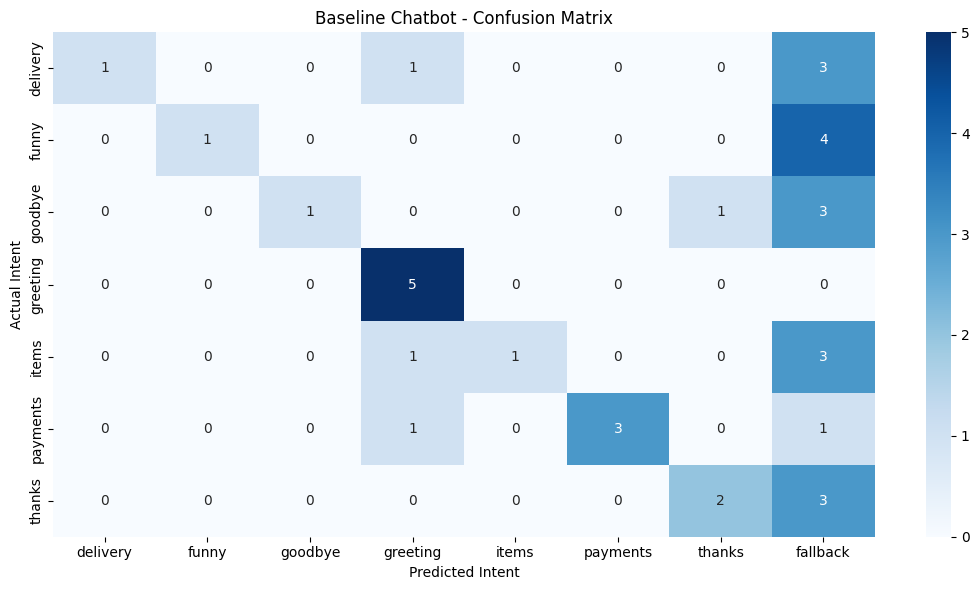

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load baseline evaluation results
df = pd.read_csv("baseline_results.csv")

# Actual intent categories
intents = sorted(df["actual_intent"].unique())

# Include fallback as a possible prediction
predicted_labels = intents + ["fallback"]

# Create confusion matrix
cm = pd.crosstab(
    df["actual_intent"],
    df["predicted_intent"]
)

cm = cm.reindex(
    index=intents,
    columns=predicted_labels,
    fill_value=0
)

# Display confusion matrix
plt.figure(figsize=(11, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Baseline Chatbot - Confusion Matrix")
plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")

plt.tight_layout()
plt.savefig("baseline_confusion_matrix.png", dpi=300)
plt.show()


In [ ]:

import pandas as pd

df = pd.read_csv("baseline_results.csv")

# Questions that triggered fallback
fallback_df = df[
    df["predicted_intent"] == "fallback"
].copy()

# Check the prediction before fallback
fallback_df["raw_correct"] = (
    fallback_df["actual_intent"] ==
    fallback_df["raw_prediction"]
)

print("Total fallback questions:", len(fallback_df))

print("Correct intents rejected:",
      fallback_df["raw_correct"].sum())

print("Incorrect intents rejected:",
      (~fallback_df["raw_correct"]).sum())

print("\nFallback analysis:")
print(fallback_df[
    ["question", "actual_intent",
     "raw_prediction", "confidence", "raw_correct"]
].to_string(index=False))


Total fallback questions: 17
Correct intents rejected: 7
Incorrect intents rejected: 10

Fallback analysis:
                             question actual_intent raw_prediction  confidence  raw_correct
         I have to leave now, goodbye       goodbye        goodbye       0.488         True
                     Talk to you soon       goodbye         thanks       0.536        False
                  I'm signing off now       goodbye       greeting       0.607        False
                     Much appreciated        thanks       greeting       0.590        False
  I really appreciate your assistance        thanks       greeting       0.607        False
               Cheers for the support        thanks       greeting       0.590        False
             What products can I buy?         items          items       0.715         True
  Can you show me your product range?         items          funny       0.615        False
       What merchandise is available?         items         than

In [ ]:

import pandas as pd

df = pd.read_csv("baseline_results.csv")

thresholds = [0.30, 0.40, 0.50, 0.60,
              0.70, 0.75, 0.80, 0.90]

results = []

for threshold in thresholds:

    # Accept predictions above the threshold
    accepted = df["confidence"] > threshold

    # Check if the model's prediction is correct
    correct = df["raw_prediction"] == df["actual_intent"]

    correct_answers = (accepted & correct).sum()
    wrong_answers = (accepted & ~correct).sum()
    fallbacks = (~accepted).sum()

    total = len(df)

    results.append({
        "Threshold": threshold,
        "Correct": correct_answers,
        "Wrong": wrong_answers,
        "Fallback": fallbacks,
        "Correct Rate (%)": round(
            correct_answers / total * 100, 2
        ),
        "Fallback Rate (%)": round(
            fallbacks / total * 100, 2
        )
    })

threshold_df = pd.DataFrame(results)

print(threshold_df.to_string(index=False))


 Threshold  Correct  Wrong  Fallback  Correct Rate (%)  Fallback Rate (%)
      0.30       21     14         0             60.00               0.00
      0.40       20     14         1             57.14               2.86
      0.50       19     13         3             54.29               8.57
      0.60       15      9        11             42.86              31.43
      0.70       15      4        16             42.86              45.71
      0.75       14      4        17             40.00              48.57
      0.80       14      4        17             40.00              48.57
      0.90       12      3        20             34.29              57.14


In [ ]:

import pandas as pd
import shutil

# Save original chatbot model
shutil.copy("data.pth", "baseline_model.pth")

# Load baseline results
df = pd.read_csv("baseline_results.csv")

# Find questions where the model predicted the wrong intent
wrong_predictions = df[
    df["actual_intent"] != df["raw_prediction"]
]

print("Total wrong intent predictions:", len(wrong_predictions))

print("\nIncorrect predictions:")
print(
    wrong_predictions[
        ["question", "actual_intent",
         "raw_prediction", "confidence"]
    ].to_string(index=False)
)

print("\nOriginal model saved as baseline_model.pth")


Total wrong intent predictions: 14

Incorrect predictions:
                             question actual_intent raw_prediction  confidence
                     Talk to you soon       goodbye         thanks       0.536
                  I'm signing off now       goodbye       greeting       0.607
                  Let's end this chat       goodbye         thanks       0.961
                     Much appreciated        thanks       greeting       0.590
  I really appreciate your assistance        thanks       greeting       0.607
               Cheers for the support        thanks       greeting       0.590
  Can you show me your product range?         items          funny       0.615
    Is there a catalogue of products?         items       greeting       0.898
       What merchandise is available?         items         thanks       0.645
  What payment methods are available?      payments         thanks       0.536
                 Is PayPal an option?      payments       greeting      

In [ ]:

import json
import copy
import pandas as pd

# Load original training data
with open("intents.json", "r") as file:
    original_data = json.load(file)

# Create a separate copy
improved_data = copy.deepcopy(original_data)

# New training examples
extra_patterns = {
    "greeting": [
        "Greetings",
        "Hey there",
        "Hello support team",
        "Hi customer service",
        "Good to see you"
    ],
    "goodbye": [
        "I'm heading out now",
        "We can finish our conversation",
        "I need to go now",
        "I'll speak to you another time",
        "End this conversation please"
    ],
    "thanks": [
        "I appreciate the help you provided",
        "You have been very helpful",
        "Thank you for assisting me today",
        "Many thanks for answering",
        "Your assistance was useful"
    ],
    "items": [
        "Could you list the items on sale",
        "Which products are available in your shop",
        "Show me what your store sells",
        "Do you have any goods for purchase",
        "Can I browse your inventory"
    ],
    "payments": [
        "Are debit cards supported",
        "Which cards are accepted",
        "Is online payment supported",
        "Can I use a bank card for checkout",
        "Can I make a payment using PayPal"
    ],
    "delivery": [
        "How many days does shipping require",
        "Can you tell me the estimated delivery date",
        "How soon is my package shipped",
        "What's the usual delivery period",
        "I want to know when my order reaches me"
    ],
    "funny": [
        "Say something that will make me laugh",
        "Could you crack a joke for me",
        "Share a silly joke",
        "Give me a funny line",
        "I'm in the mood for humour"
    ]
}

# Ensure new questions are not in development data
development = pd.read_csv("development_questions.csv")
development_texts = set(
    development["question"].str.strip().str.lower()
)

for intent in improved_data["intents"]:
    tag = intent["tag"]

    existing = set(
        text.strip().lower()
        for text in intent["patterns"]
    )

    for question in extra_patterns[tag]:
        normalized = question.strip().lower()

        assert normalized not in development_texts
        assert normalized not in existing

        intent["patterns"].append(question)

# Save separately without replacing original
with open("intents_optimized.json", "w") as file:
    json.dump(improved_data, file, indent=4)

# Display training pattern counts
for intent in improved_data["intents"]:
    print(intent["tag"], ":", len(intent["patterns"]))

print("\nTotal training patterns:",
      sum(len(i["patterns"]) for i in improved_data["intents"]))

print("Optimized dataset saved successfully!")


greeting : 11
goodbye : 8
thanks : 9
items : 8
payments : 9
delivery : 8
funny : 8

Total training patterns: 61
Optimized dataset saved successfully!


In [ ]:

import shutil
import subprocess
import sys
import os

# Back up the original training dataset
shutil.copyfile("intents.json", "intents_original.json")

try:
    # Use the improved training dataset
    shutil.copyfile("intents_optimized.json", "intents.json")

    # Train the optimized chatbot
    subprocess.run([sys.executable, "train.py"], check=True)

    # Save the optimized model separately
    shutil.copyfile("data.pth", "optimized_model.pth")

finally:
    # Restore original training dataset
    shutil.copyfile("intents_original.json", "intents.json")

print("\nOptimized model saved successfully!")
print("Baseline model:", os.path.exists("baseline_model.pth"))
print("Optimized model:", os.path.exists("optimized_model.pth"))



Optimized model saved successfully!
Baseline model: True
Optimized model: True


In [ ]:

import torch
import pandas as pd
from model import NeuralNet
from nltk_utils import tokenize, bag_of_words

# Load development questions
df = pd.read_csv("development_questions.csv")

def evaluate_model(model_file):

    # Load trained model and its vocabulary
    data = torch.load(
        model_file,
        map_location="cpu",
        weights_only=True
    )

    model = NeuralNet(
        data["input_size"],
        data["hidden_size"],
        data["output_size"]
    )

    model.load_state_dict(data["model_state"])
    model.eval()

    results = []

    for _, row in df.iterrows():

        question = row["question"]
        actual = row["actual_intent"]

        tokens = tokenize(question)
        X = bag_of_words(tokens, data["all_words"])
        X = torch.from_numpy(X).reshape(1, -1).float()

        with torch.no_grad():
            output = model(X)
            probs = torch.softmax(output, dim=1)
            confidence, index = torch.max(probs, dim=1)

        raw_prediction = data["tags"][index.item()]
        score = confidence.item()

        if score > 0.75:
            prediction = raw_prediction
        else:
            prediction = "fallback"

        results.append({
            "question": question,
            "actual_intent": actual,
            "raw_prediction": raw_prediction,
            "predicted_intent": prediction,
            "confidence": score
        })

    result_df = pd.DataFrame(results)

    raw_correct = (
        result_df["actual_intent"] ==
        result_df["raw_prediction"]
    )

    final_correct = (
        result_df["actual_intent"] ==
        result_df["predicted_intent"]
    )

    fallback = (
        result_df["predicted_intent"] == "fallback"
    )

    metrics = {
        "Raw Accuracy (%)": round(raw_correct.mean()*100, 2),
        "Final Accuracy (%)": round(final_correct.mean()*100, 2),
        "Fallback Rate (%)": round(fallback.mean()*100, 2),
        "Correct": int(final_correct.sum()),
        "Wrong": int((~final_correct & ~fallback).sum()),
        "Fallback": int(fallback.sum())
    }

    return metrics, result_df


# Evaluate both models
baseline_metrics, baseline_df = evaluate_model(
    "baseline_model.pth"
)

optimized_metrics, optimized_df = evaluate_model(
    "optimized_model.pth"
)

# Save optimized results
optimized_df.to_csv(
    "optimized_development_results.csv",
    index=False
)

# Comparison table
comparison = pd.DataFrame({
    "Baseline": baseline_metrics,
    "Optimized": optimized_metrics
})

print("CHATBOT PERFORMANCE COMPARISON")
print(comparison)


CHATBOT PERFORMANCE COMPARISON
                    Baseline  Optimized
Raw Accuracy (%)       60.00      82.86
Final Accuracy (%)     40.00      80.00
Fallback Rate (%)      48.57      17.14
Correct                14.00      28.00
Wrong                   4.00       1.00
Fallback               17.00       6.00


In [ ]:

import json
import pandas as pd

test_questions = {
    "greeting": [
        "Hi there, can we chat?",
        "Hello, I just arrived",
        "Morning, anyone here?",
        "Hey support, are you online?",
        "Greetings from a new customer",
        "Hello again, assistant",
        "Hi, I need some help",
        "Good evening to the support staff",
        "Hey bot, how's it going?",
        "Hello, may I ask something?"
    ],
    "goodbye": [
        "I am done chatting for today",
        "Farewell, assistant",
        "Catch you another time",
        "That is all, bye for now",
        "I must disconnect now",
        "We are finished talking",
        "I will return another day",
        "Signing out, see you",
        "No more questions, farewell",
        "I am leaving this conversation"
    ],
    "thanks": [
        "Thanks a million",
        "That was very kind of you",
        "I am thankful for the information",
        "You've helped me a great deal",
        "My sincere thanks to you",
        "I am very grateful",
        "I value your assistance",
        "Thank you so much for explaining",
        "That really helped, thanks",
        "Please accept my thanks"
    ],
    "items": [
        "What can customers purchase here?",
        "What types of goods do you carry?",
        "May I see a list of products?",
        "What is currently available to buy?",
        "Tell me about your product selection",
        "Do you offer different categories of goods?",
        "Which things are sold in this store?",
        "I would like to explore your inventory",
        "What products does your business offer?",
        "Show me the available merchandise"
    ],
    "payments": [
        "Can customers use Visa at checkout?",
        "Is it possible to pay electronically?",
        "Which payment options do you support?",
        "Will you accept a bank transfer?",
        "Can my purchase be paid by card?",
        "Is cash payment possible?",
        "What are the available ways to pay?",
        "Do you support contactless payments?",
        "Can I complete checkout with a credit card?",
        "Is payment through an online wallet accepted?"
    ],
    "delivery": [
        "Approximately when will my order arrive?",
        "How many working days is shipping?",
        "How much time does delivery usually need?",
        "Can you estimate when my parcel gets here?",
        "What is the normal shipping duration?",
        "How long before the goods reach my address?",
        "When can I expect the shipment?",
        "Is the delivery period several days?",
        "How soon can my purchase arrive?",
        "Tell me the approximate delivery time"
    ],
    "funny": [
        "Could you entertain me with a joke?",
        "Please say something hilarious",
        "I need a good laugh right now",
        "Do you have any jokes to share?",
        "Tell a joke to cheer me up",
        "Can you make this conversation amusing?",
        "Share something comical with me",
        "Know any hilarious one-liners?",
        "Please tell me a silly story",
        "Give me something funny to hear"
    ]
}

out_of_scope = [
    "Please reset my account password",
    "I want to request a full refund",
    "Can I speak to a human manager?",
    "Please cancel my latest purchase",
    "What is the weather forecast tomorrow?",
    "Can you translate this into German?",
    "How can I change my email address?",
    "What is 19 multiplied by 27?",
    "Where is the nearest railway station?",
    "Help me repair my broken laptop",
    "Can you change my billing address?",
    "What are your store opening hours?",
    "Please delete my customer account",
    "I want to report a security problem",
    "How can I exchange a damaged item?"
]

# Build the evaluation dataset
rows = []

for intent, questions in test_questions.items():
    for question in questions:
        rows.append({
            "question": question,
            "actual_intent": intent,
            "test_type": "in_scope"
        })

for question in out_of_scope:
    rows.append({
        "question": question,
        "actual_intent": "out_of_scope",
        "test_type": "out_of_scope"
    })

final_test_df = pd.DataFrame(rows)

# Check for exact duplicates
with open("intents_optimized.json") as f:
    train_data = json.load(f)

training_questions = {
    q.strip().lower()
    for intent in train_data["intents"]
    for q in intent["patterns"]
}

development_questions = set(
    pd.read_csv("development_questions.csv")["question"]
    .str.strip().str.lower()
)

new_questions = final_test_df["question"].str.strip().str.lower()

assert new_questions.is_unique
assert not set(new_questions) & training_questions
assert not set(new_questions) & development_questions

# Save final test data
final_test_df.to_csv("final_test_questions.csv", index=False)

print("Final test dataset created!")
print("Total questions:", len(final_test_df))
print("In-scope questions:",
      (final_test_df["test_type"] == "in_scope").sum())
print("Out-of-scope questions:",
      (final_test_df["test_type"] == "out_of_scope").sum())

print("\nIntent distribution:")
print(final_test_df["actual_intent"].value_counts())



Final test dataset created!
Total questions: 85
In-scope questions: 70
Out-of-scope questions: 15

Intent distribution:
actual_intent
out_of_scope    15
greeting        10
thanks          10
goodbye         10
items           10
payments        10
delivery        10
funny           10
Name: count, dtype: int64


In [ ]:

import torch
import pandas as pd
from model import NeuralNet
from nltk_utils import tokenize, bag_of_words

# Load final test dataset
test_df = pd.read_csv("final_test_questions.csv")

def final_evaluation(model_file):

    data = torch.load(
        model_file,
        map_location="cpu",
        weights_only=True
    )

    model = NeuralNet(
        data["input_size"],
        data["hidden_size"],
        data["output_size"]
    )

    model.load_state_dict(data["model_state"])
    model.eval()

    results = []

    for _, row in test_df.iterrows():

        question = row["question"]

        tokens = tokenize(question)
        X = bag_of_words(tokens, data["all_words"])
        X = torch.from_numpy(X).reshape(1, -1).float()

        with torch.no_grad():
            output = model(X)
            probabilities = torch.softmax(output, dim=1)
            confidence, index = torch.max(probabilities, dim=1)

        raw_prediction = data["tags"][index.item()]
        score = confidence.item()

        prediction = (
            raw_prediction if score > 0.75
            else "fallback"
        )

        results.append({
            "question": question,
            "actual_intent": row["actual_intent"],
            "test_type": row["test_type"],
            "raw_prediction": raw_prediction,
            "predicted_intent": prediction,
            "confidence": score
        })

    result_df = pd.DataFrame(results)

    # Separate supported and unsupported questions
    inside = result_df[
        result_df["test_type"] == "in_scope"
    ]

    outside = result_df[
        result_df["test_type"] == "out_of_scope"
    ]

    # In-scope metrics
    raw_accuracy = (
        inside["raw_prediction"] == inside["actual_intent"]
    ).mean() * 100

    final_accuracy = (
        inside["predicted_intent"] == inside["actual_intent"]
    ).mean() * 100

    fallback_rate = (
        inside["predicted_intent"] == "fallback"
    ).mean() * 100

    wrong_answers = (
        (inside["predicted_intent"] != inside["actual_intent"]) &
        (inside["predicted_intent"] != "fallback")
    ).sum()

    # Out-of-scope rejection rate
    oos_rejection = (
        outside["predicted_intent"] == "fallback"
    ).mean() * 100

    # Overall correct decisions
    correct_inside = (
        inside["predicted_intent"] == inside["actual_intent"]
    ).sum()

    correct_outside = (
        outside["predicted_intent"] == "fallback"
    ).sum()

    overall_accuracy = (
        (correct_inside + correct_outside)
        / len(result_df) * 100
    )

    metrics = {
        "Raw Intent Accuracy (%)": round(raw_accuracy, 2),
        "Final Intent Accuracy (%)": round(final_accuracy, 2),
        "In-Scope Fallback Rate (%)": round(fallback_rate, 2),
        "Wrong In-Scope Answers": int(wrong_answers),
        "Out-of-Scope Rejection (%)": round(oos_rejection, 2),
        "Overall Decision Accuracy (%)": round(overall_accuracy, 2)
    }

    return metrics, result_df


# Evaluate both trained models
baseline_metrics, baseline_results = final_evaluation(
    "baseline_model.pth"
)

optimized_metrics, optimized_results = final_evaluation(
    "optimized_model.pth"
)

# Save the results
baseline_results.to_csv(
    "baseline_final_test_results.csv", index=False
)

optimized_results.to_csv(
    "optimized_final_test_results.csv", index=False
)

# Display comparison
comparison = pd.DataFrame({
    "Baseline": baseline_metrics,
    "Optimized": optimized_metrics
})

print("FINAL CHATBOT PERFORMANCE COMPARISON")
print(comparison.to_string())



FINAL CHATBOT PERFORMANCE COMPARISON
                               Baseline  Optimized
Raw Intent Accuracy (%)           47.14      71.43
Final Intent Accuracy (%)         37.14      67.14
In-Scope Fallback Rate (%)        47.14      21.43
Wrong In-Scope Answers            11.00       8.00
Out-of-Scope Rejection (%)        73.33      46.67
Overall Decision Accuracy (%)     43.53      63.53


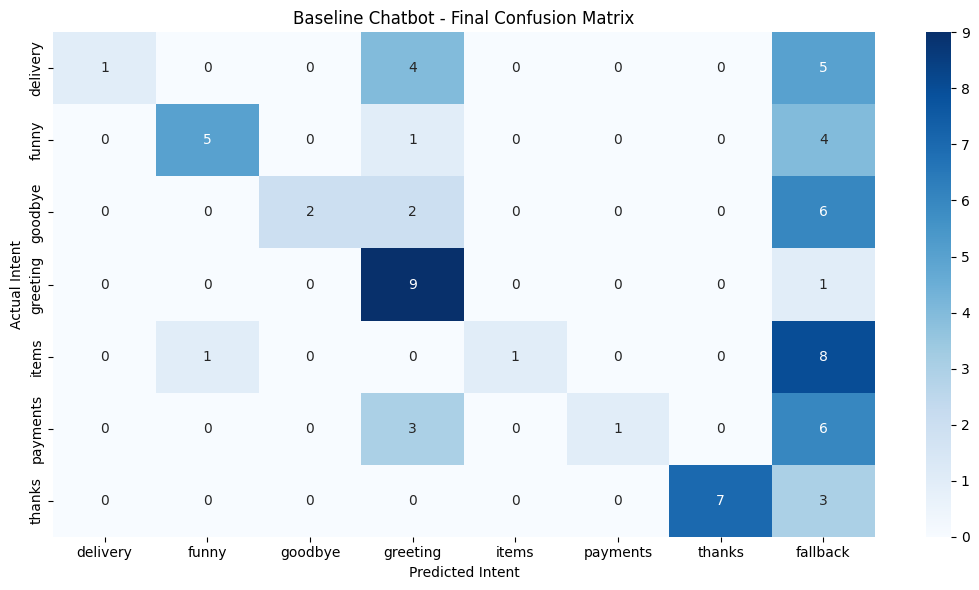

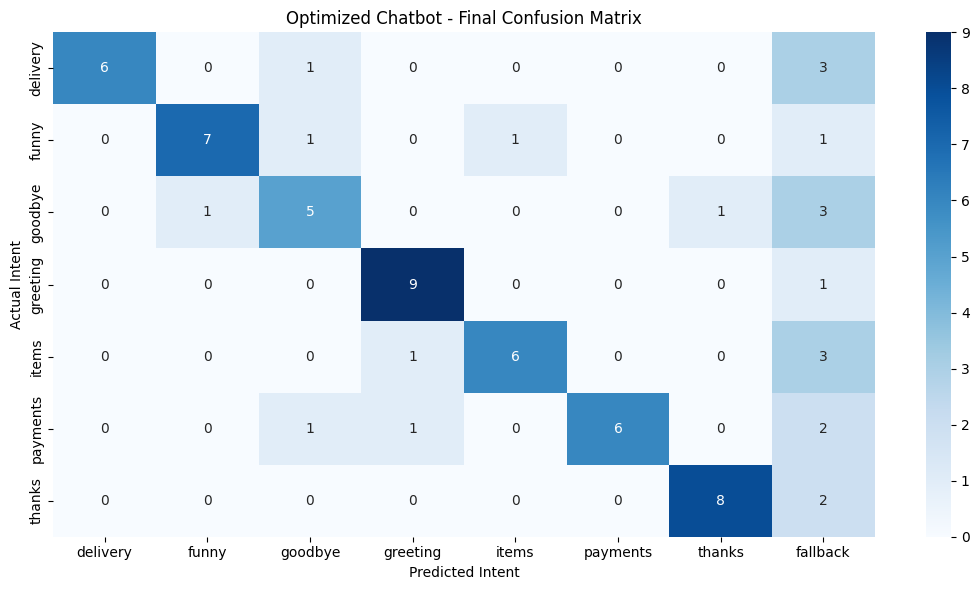

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load final test results
baseline = pd.read_csv("baseline_final_test_results.csv")
optimized = pd.read_csv("optimized_final_test_results.csv")

models = {
    "Baseline Chatbot": baseline,
    "Optimized Chatbot": optimized
}

for name, df in models.items():

    # Use only supported intents
    inside = df[df["test_type"] == "in_scope"]

    intents = sorted(inside["actual_intent"].unique())
    predictions = intents + ["fallback"]

    # Create confusion matrix
    cm = pd.crosstab(
        inside["actual_intent"],
        inside["predicted_intent"]
    )

    cm = cm.reindex(
        index=intents,
        columns=predictions,
        fill_value=0
    )

    # Plot confusion matrix
    plt.figure(figsize=(11, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    plt.title(name + " - Final Confusion Matrix")
    plt.xlabel("Predicted Intent")
    plt.ylabel("Actual Intent")

    plt.tight_layout()

    filename = name.lower().replace(" ", "_")
    plt.savefig(filename + "_confusion.png", dpi=300)

    plt.show()




In [ ]:

import pandas as pd
from sklearn.metrics import classification_report

baseline = pd.read_csv("baseline_final_test_results.csv")
optimized = pd.read_csv("optimized_final_test_results.csv")

models = {
    "Baseline": baseline,
    "Optimized": optimized
}

intents = [
    "delivery", "funny", "goodbye",
    "greeting", "items", "payments", "thanks"
]

for name, df in models.items():

    # Use only supported questions
    df = df[df["test_type"] == "in_scope"]

    print("\n", name, "CHATBOT")
    print("------------------------------")

    report = classification_report(
        df["actual_intent"],
        df["predicted_intent"],
        labels=intents,
        zero_division=0,
        output_dict=True
    )

    # Show metrics for each intent
    rows = []

    for intent in intents:
        rows.append({
            "Intent": intent,
            "Precision": round(report[intent]["precision"], 3),
            "Recall": round(report[intent]["recall"], 3),
            "F1-score": round(report[intent]["f1-score"], 3)
        })

    metrics_df = pd.DataFrame(rows)

    print(metrics_df.to_string(index=False))

    print("\nMacro F1-score:",
          round(report["macro avg"]["f1-score"], 3))

    # Save results
    metrics_df.to_csv(
        name.lower() + "_classification_metrics.csv",
        index=False
    )



 Baseline CHATBOT
------------------------------
  Intent  Precision  Recall  F1-score
delivery      1.000     0.1     0.182
   funny      0.833     0.5     0.625
 goodbye      1.000     0.2     0.333
greeting      0.474     0.9     0.621
   items      1.000     0.1     0.182
payments      1.000     0.1     0.182
  thanks      1.000     0.7     0.824

Macro F1-score: 0.421

 Optimized CHATBOT
------------------------------
  Intent  Precision  Recall  F1-score
delivery      1.000     0.6     0.750
   funny      0.875     0.7     0.778
 goodbye      0.625     0.5     0.556
greeting      0.818     0.9     0.857
   items      0.857     0.6     0.706
payments      1.000     0.6     0.750
  thanks      0.889     0.8     0.842

Macro F1-score: 0.748


In [ ]:

import time
import json
import torch
import pandas as pd

from model import NeuralNet
from nltk_utils import tokenize, bag_of_words

# Load final test questions
test_df = pd.read_csv("final_test_questions.csv")

# Load chatbot responses
with open("intents.json", "r") as f:
    intents_data = json.load(f)

responses = {
    item["tag"]: item["responses"]
    for item in intents_data["intents"]
}

def load_chatbot(filename):
    data = torch.load(
        filename,
        map_location="cpu",
        weights_only=True
    )

    model = NeuralNet(
        data["input_size"],
        data["hidden_size"],
        data["output_size"]
    )

    model.load_state_dict(data["model_state"])
    model.eval()

    return model, data


def get_response(question, model, data):
    tokens = tokenize(question)
    X = bag_of_words(tokens, data["all_words"])
    X = torch.from_numpy(X).reshape(1, -1).float()

    with torch.inference_mode():
        output = model(X)
        probs = torch.softmax(output, dim=1)
        confidence, index = torch.max(probs, dim=1)

    intent = data["tags"][index.item()]

    if confidence.item() <= 0.75:
        return "I do not understand."

    return responses[intent][0]


# Compare response times
models = {
    "Baseline": "baseline_model.pth",
    "Optimized": "optimized_model.pth"
}

timing_results = []

for name, filename in models.items():
    model, data = load_chatbot(filename)

    # Warm up the model
    for question in test_df["question"].head(10):
        get_response(question, model, data)

    # Repeat testing 5 times
    for run in range(5):
        for question in test_df["question"]:

            start = time.perf_counter()

            response = get_response(
                question, model, data
            )

            end = time.perf_counter()

            timing_results.append({
                "Model": name,
                "Response_Time_ms": (end - start) * 1000
            })

# Save response-time records
timing_df = pd.DataFrame(timing_results)
timing_df.to_csv("response_times.csv", index=False)

# Calculate statistics
summary = timing_df.groupby("Model")[
    "Response_Time_ms"
].agg(["mean", "median", "min", "max"])

summary["p95"] = timing_df.groupby("Model")[
    "Response_Time_ms"
].quantile(0.95)

print("CHATBOT RESPONSE TIME COMPARISON (ms)")
print(summary.round(3))


CHATBOT RESPONSE TIME COMPARISON (ms)
            mean  median    min    max    p95
Model                                        
Baseline   0.739   0.470  0.348  6.921  2.604
Optimized  0.553   0.487  0.237  2.769  0.607


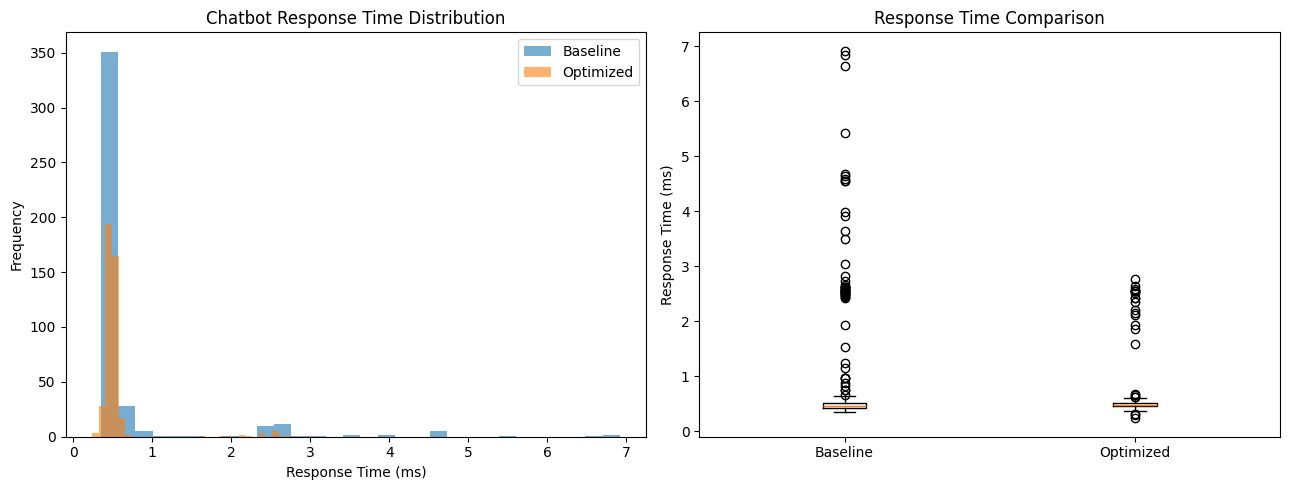

Baseline
Total measurements: 425
Measurements over 1 ms: 41
Percentage over 1 ms: 9.65
--------------------------
Optimized
Total measurements: 425
Measurements over 1 ms: 16
Percentage over 1 ms: 3.76
--------------------------


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Load response-time measurements
df = pd.read_csv("response_times.csv")

baseline = df[df["Model"] == "Baseline"]["Response_Time_ms"]
optimized = df[df["Model"] == "Optimized"]["Response_Time_ms"]

# Create two charts
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Chart 1: Histogram
axes[0].hist(baseline, bins=30, alpha=0.6, label="Baseline")
axes[0].hist(optimized, bins=30, alpha=0.6, label="Optimized")

axes[0].set_title("Chatbot Response Time Distribution")
axes[0].set_xlabel("Response Time (ms)")
axes[0].set_ylabel("Frequency")
axes[0].legend()

# Chart 2: Box plot
axes[1].boxplot([baseline, optimized])
axes[1].set_xticks([1, 2])
axes[1].set_xticklabels(["Baseline", "Optimized"])

axes[1].set_title("Response Time Comparison")
axes[1].set_ylabel("Response Time (ms)")

plt.tight_layout()
plt.savefig("response_time_eda.png", dpi=300)
plt.show()

# Identify relatively slow processing measurements
for name, values in [
    ("Baseline", baseline),
    ("Optimized", optimized)
]:
    slow = (values > 1.0).sum()

    print(name)
    print("Total measurements:", len(values))
    print("Measurements over 1 ms:", slow)
    print("Percentage over 1 ms:",
          round(slow / len(values) * 100, 2))
    print("--------------------------")



INTENT-WISE PERFORMANCE COMPARISON
               Baseline Accuracy (%)  Optimized Accuracy (%)  Improvement (pp)
actual_intent                                                                 
delivery                        10.0                    60.0              50.0
funny                           50.0                    70.0              20.0
goodbye                         20.0                    50.0              30.0
greeting                        90.0                    90.0               0.0
items                           10.0                    60.0              50.0
payments                        10.0                    60.0              50.0
thanks                          70.0                    80.0              10.0


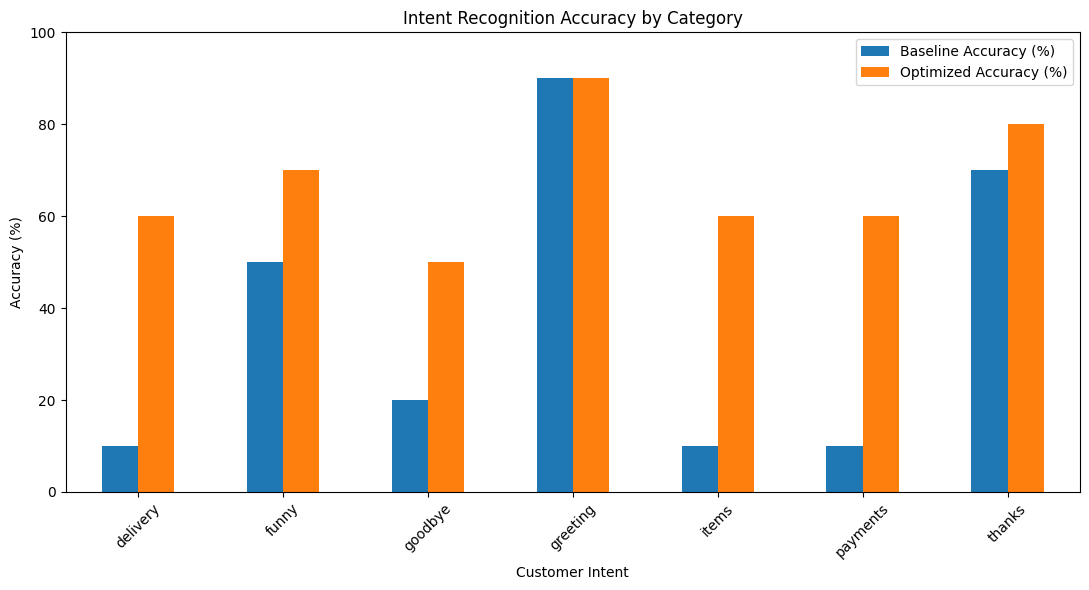

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Load final test results
baseline = pd.read_csv("baseline_final_test_results.csv")
optimized = pd.read_csv("optimized_final_test_results.csv")

# Use only supported intents
baseline = baseline[baseline["test_type"] == "in_scope"].copy()
optimized = optimized[optimized["test_type"] == "in_scope"].copy()

# Calculate correctness
baseline["correct"] = (
    baseline["actual_intent"] == baseline["predicted_intent"]
)

optimized["correct"] = (
    optimized["actual_intent"] == optimized["predicted_intent"]
)

# Calculate accuracy for each intent
baseline_accuracy = baseline.groupby("actual_intent")["correct"].mean() * 100
optimized_accuracy = optimized.groupby("actual_intent")["correct"].mean() * 100

# Create comparison table
intent_comparison = pd.DataFrame({
    "Baseline Accuracy (%)": baseline_accuracy,
    "Optimized Accuracy (%)": optimized_accuracy
})

intent_comparison["Improvement (pp)"] = (
    intent_comparison["Optimized Accuracy (%)"] -
    intent_comparison["Baseline Accuracy (%)"]
)

print("INTENT-WISE PERFORMANCE COMPARISON")
print(intent_comparison.round(2).to_string())

# Create comparison chart
intent_comparison[
    ["Baseline Accuracy (%)", "Optimized Accuracy (%)"]
].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Intent Recognition Accuracy by Category")
plt.xlabel("Customer Intent")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

plt.savefig("intent_accuracy_comparison.png", dpi=300)
plt.show()

# Save results
intent_comparison.to_csv("intent_comparison.csv")


FALLBACK ANALYSIS BY INTENT
               Baseline Fallback (%)  Optimized Fallback (%)  Change (pp)
actual_intent                                                            
delivery                       50.00                   30.00       -20.00
funny                          40.00                   10.00       -30.00
goodbye                        60.00                   30.00       -30.00
greeting                       10.00                   10.00         0.00
items                          80.00                   30.00       -50.00
out_of_scope                   73.33                   46.67       -26.67
payments                       60.00                   20.00       -40.00
thanks                         30.00                   20.00       -10.00


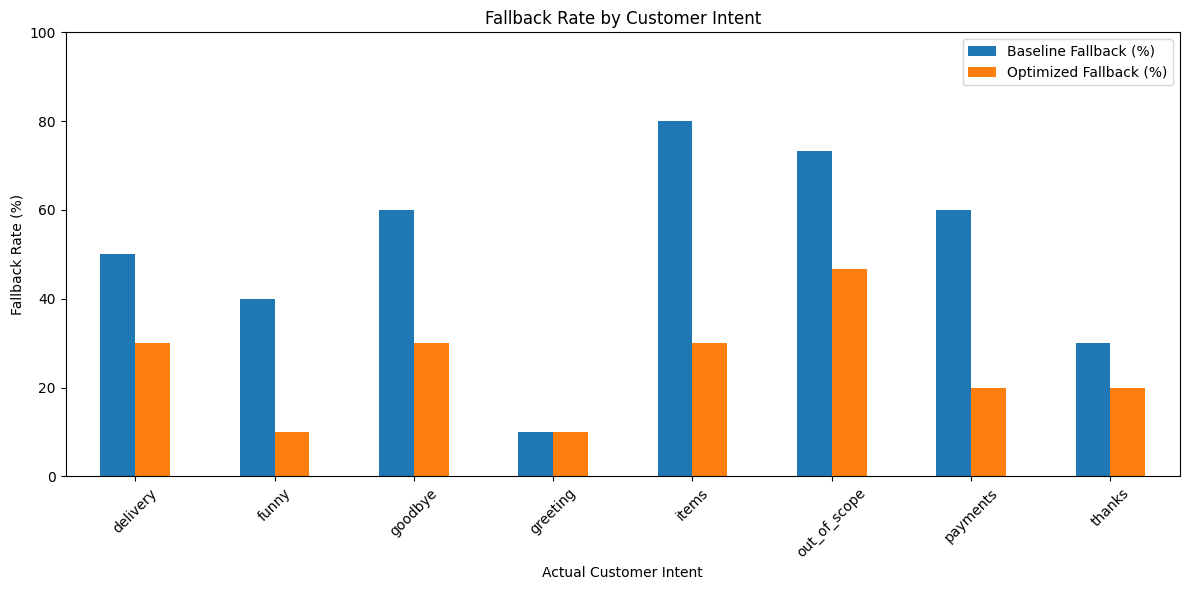

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Load chatbot evaluation results
baseline = pd.read_csv("baseline_final_test_results.csv")
optimized = pd.read_csv("optimized_final_test_results.csv")

# Calculate fallback rate for each intent
baseline["fallback"] = (
    baseline["predicted_intent"] == "fallback"
)

optimized["fallback"] = (
    optimized["predicted_intent"] == "fallback"
)

baseline_rates = (
    baseline.groupby("actual_intent")["fallback"].mean() * 100
)

optimized_rates = (
    optimized.groupby("actual_intent")["fallback"].mean() * 100
)

# Create comparison table
fallback_comparison = pd.DataFrame({
    "Baseline Fallback (%)": baseline_rates,
    "Optimized Fallback (%)": optimized_rates
})

fallback_comparison["Change (pp)"] = (
    fallback_comparison["Optimized Fallback (%)"] -
    fallback_comparison["Baseline Fallback (%)"]
)

print("FALLBACK ANALYSIS BY INTENT")
print(fallback_comparison.round(2).to_string())

# Create graph
fallback_comparison[
    ["Baseline Fallback (%)", "Optimized Fallback (%)"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Fallback Rate by Customer Intent")
plt.xlabel("Actual Customer Intent")
plt.ylabel("Fallback Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

plt.savefig("fallback_analysis.png", dpi=300)
plt.show()

# Save the results
fallback_comparison.to_csv("fallback_comparison.csv")


In [ ]:

import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Load final evaluation results
baseline = pd.read_csv("baseline_final_test_results.csv")
optimized = pd.read_csv("optimized_final_test_results.csv")

# Separate supported questions
b_in = baseline[baseline["test_type"] == "in_scope"].copy()
o_in = optimized[optimized["test_type"] == "in_scope"].copy()

# Calculate performance metrics
def calculate_metrics(df):
    inside = df[df["test_type"] == "in_scope"]
    outside = df[df["test_type"] == "out_of_scope"]

    return {
        "raw": (
            inside["raw_prediction"] == inside["actual_intent"]
        ).mean() * 100,

        "final": (
            inside["predicted_intent"] == inside["actual_intent"]
        ).mean() * 100,

        "fallback": (
            inside["predicted_intent"] == "fallback"
        ).mean() * 100,

        "oos": (
            outside["predicted_intent"] == "fallback"
        ).mean() * 100
    }

b = calculate_metrics(baseline)
o = calculate_metrics(optimized)

# Calculate accuracy by intent
intents = sorted(b_in["actual_intent"].unique())

b_intent = (
    b_in.assign(
        correct=b_in["actual_intent"] == b_in["predicted_intent"]
    )
    .groupby("actual_intent")["correct"]
    .mean()
    .reindex(intents) * 100
)

o_intent = (
    o_in.assign(
        correct=o_in["actual_intent"] == o_in["predicted_intent"]
    )
    .groupby("actual_intent")["correct"]
    .mean()
    .reindex(intents) * 100
)

# Create dashboard layout
fig = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=[
        "Intent Recognition Accuracy",
        "In-Scope Fallback Rate",
        "Accuracy by Customer Intent",
        "Out-of-Scope Rejection Rate"
    ],
    vertical_spacing=0.18,
    horizontal_spacing=0.12
)

colors = {
    "Baseline": "#3274B5",
    "Optimized": "#EE8938"
}

# Add comparison bars to each chart
def add_comparison(x, base, opt, row, col, legend=False):
    for name, values in [
        ("Baseline", base),
        ("Optimized", opt)
    ]:
        fig.add_trace(
            go.Bar(
                x=x,
                y=values,
                name=name,
                marker_color=colors[name],
                legendgroup=name,
                showlegend=legend,
                hovertemplate="%{x}: %{y:.1f}%<extra>" + name + "</extra>"
            ),
            row=row,
            col=col
        )

# Chart 1: Accuracy
add_comparison(
    ["Raw Accuracy", "Final Accuracy"],
    [b["raw"], b["final"]],
    [o["raw"], o["final"]],
    1, 1, legend=True
)

# Chart 2: In-scope fallback
add_comparison(
    ["Fallback"],
    [b["fallback"]],
    [o["fallback"]],
    1, 2
)

# Chart 3: Intent-wise accuracy
add_comparison(
    intents,
    b_intent.tolist(),
    o_intent.tolist(),
    2, 1
)

# Chart 4: Out-of-scope rejection
add_comparison(
    ["Rejection"],
    [b["oos"]],
    [o["oos"]],
    2, 2
)

# Consistent percentage axes
for r in [1, 2]:
    for c in [1, 2]:
        fig.update_yaxes(
            range=[0, 100],
            ticksuffix="%",
            row=r,
            col=c
        )

# Dashboard design
fig.update_layout(
    title={
        "text": "Customer Support Chatbot Analytics Dashboard",
        "x": 0.5
    },
    barmode="group",
    height=850,
    width=1150,
    template="plotly_white",
    legend=dict(
        orientation="h",
        y=1.08,
        x=0.5,
        xanchor="center"
    )
)

fig.show()

# Save interactive dashboard
fig.write_html("chatbot_analytics_dashboard.html")

print("Dashboard created successfully!")


Dashboard created successfully!


In [ ]:

import pandas as pd

sessions = {
    "S01": [
        ("Which goods do you offer customers?", "items"),
        ("Can I use my debit card to purchase one?", "payments")
    ],
    "S02": [
        ("What is the typical delivery duration?", "delivery"),
        ("Can I pay for an order with Mastercard?", "payments")
    ],
    "S03": [
        ("What products are sold in your shop?", "items"),
        ("How soon will those products arrive?", "delivery")
    ],
    "S04": [
        ("Can I make a payment with a card?", "payments"),
        ("Which merchandise can I order?", "items")
    ],
    "S05": [
        ("How many days will my parcel take?", "delivery"),
        ("Which payment methods can I choose?", "payments")
    ],
    "S06": [
        ("What goods do you currently sell?", "items"),
        ("Can you tell me the shipping duration?", "delivery")
    ],
    "S07": [
        ("Do you allow online card payments?", "payments"),
        ("What is the usual shipping time?", "delivery")
    ],
    "S08": [
        ("Can I browse the products you carry?", "items"),
        ("Is paying by credit card allowed?", "payments")
    ],
    "S09": [
        ("When should my delivery reach me?", "delivery"),
        ("What things are available for purchase?", "items")
    ],
    "S10": [
        ("How can customers pay for their orders?", "payments"),
        ("How long does the delivery process take?", "delivery")
    ]
}

rows = []

for session_id, questions in sessions.items():
    for turn, (question, intent) in enumerate(questions, 1):
        rows.append({
            "session_id": session_id,
            "turn": turn,
            "question": question,
            "expected_intent": intent
        })

session_df = pd.DataFrame(rows)

session_df.to_csv(
    "simulated_sessions.csv",
    index=False
)

print("Total simulated sessions:",
      session_df["session_id"].nunique())

print("Total customer messages:", len(session_df))

print("\nFirst 6 records:")
print(session_df.head(6).to_string(index=False))


Total simulated sessions: 10
Total customer messages: 20

First 6 records:
session_id  turn                                 question expected_intent
       S01     1      Which goods do you offer customers?           items
       S01     2 Can I use my debit card to purchase one?        payments
       S02     1   What is the typical delivery duration?        delivery
       S02     2  Can I pay for an order with Mastercard?        payments
       S03     1     What products are sold in your shop?           items
       S03     2     How soon will those products arrive?        delivery


In [ ]:

import pandas as pd
import torch

from model import NeuralNet
from nltk_utils import tokenize, bag_of_words

# Load simulated conversations
sessions = pd.read_csv("simulated_sessions.csv")

def evaluate_sessions(model_file, model_name):

    # Load trained model
    data = torch.load(
        model_file,
        map_location="cpu",
        weights_only=True
    )

    model = NeuralNet(
        data["input_size"],
        data["hidden_size"],
        data["output_size"]
    )

    model.load_state_dict(data["model_state"])
    model.eval()

    results = []

    for _, row in sessions.iterrows():

        question = row["question"]

        # NLP preprocessing
        tokens = tokenize(question)
        X = bag_of_words(tokens, data["all_words"])
        X = torch.from_numpy(X).reshape(1, -1).float()

        # Predict intent
        with torch.no_grad():
            output = model(X)
            probabilities = torch.softmax(output, dim=1)
            confidence, index = torch.max(probabilities, dim=1)

        predicted = data["tags"][index.item()]
        score = confidence.item()

        # Apply original threshold
        if score <= 0.75:
            predicted = "fallback"

        correct = predicted == row["expected_intent"]

        results.append({
            "session_id": row["session_id"],
            "turn": row["turn"],
            "expected_intent": row["expected_intent"],
            "predicted_intent": predicted,
            "correct": correct
        })

    results_df = pd.DataFrame(results)

    # Session succeeds only if every turn is correct
    session_success = (
        results_df.groupby("session_id")["correct"].all()
    )

    success_rate = session_success.mean() * 100

    # Save results
    results_df.to_csv(
        model_name.lower() + "_session_results.csv",
        index=False
    )

    print("\n", model_name, "CHATBOT")
    print("Successful sessions:", session_success.sum())
    print("Total sessions:", len(session_success))
    print("Session Success Rate:", round(success_rate, 2), "%")

    return session_success, success_rate


# Evaluate both chatbots
baseline_sessions, baseline_rate = evaluate_sessions(
    "baseline_model.pth", "Baseline"
)

optimized_sessions, optimized_rate = evaluate_sessions(
    "optimized_model.pth", "Optimized"
)

# Compare performance
comparison = pd.DataFrame({
    "Baseline": baseline_sessions,
    "Optimized": optimized_sessions
})

print("\nSESSION-BY-SESSION COMPARISON")
print(comparison.to_string())

print("\nSESSION SUCCESS RATE COMPARISON")
print("Baseline:", round(baseline_rate, 2), "%")
print("Optimized:", round(optimized_rate, 2), "%")



 Baseline CHATBOT
Successful sessions: 1
Total sessions: 10
Session Success Rate: 10.0 %

 Optimized CHATBOT
Successful sessions: 4
Total sessions: 10
Session Success Rate: 40.0 %

SESSION-BY-SESSION COMPARISON
            Baseline  Optimized
session_id                     
S01            False      False
S02             True       True
S03            False      False
S04            False      False
S05            False      False
S06            False      False
S07            False       True
S08            False       True
S09            False       True
S10            False      False

SESSION SUCCESS RATE COMPARISON
Baseline: 10.0 %
Optimized: 40.0 %


In [ ]:

import pandas as pd
import plotly.graph_objects as go

# Load the saved session results
baseline = pd.read_csv("baseline_session_results.csv")
optimized = pd.read_csv("optimized_session_results.csv")

models = {
    "Baseline": baseline,
    "Optimized": optimized
}

results = []

for name, df in models.items():

    # Ensure correct column contains Boolean values
    df["correct"] = (
        df["correct"].astype(str).str.lower() == "true"
    )

    # Calculate individual question success
    turn_success = df["correct"].mean() * 100

    # Calculate full session success
    session_success = (
        df.groupby("session_id")["correct"].all()
    )

    session_rate = session_success.mean() * 100

    results.append({
        "Model": name,
        "Turn Success (%)": round(turn_success, 2),
        "Session Success (%)": round(session_rate, 2),
        "Successful Sessions": int(session_success.sum())
    })

# Create summary table
summary = pd.DataFrame(results)

print("SESSION PERFORMANCE COMPARISON")
print(summary.to_string(index=False))

# Create visualization
fig_sessions = go.Figure()

fig_sessions.add_trace(go.Bar(
    x=summary["Model"],
    y=summary["Turn Success (%)"],
    name="Individual Question Success",
    marker_color="#3274B5",
    text=summary["Turn Success (%)"],
    texttemplate="%{text:.1f}%",
    textposition="outside"
))

fig_sessions.add_trace(go.Bar(
    x=summary["Model"],
    y=summary["Session Success (%)"],
    name="Two-Turn Session Success",
    marker_color="#EE8938",
    text=summary["Session Success (%)"],
    texttemplate="%{text:.1f}%",
    textposition="outside"
))

fig_sessions.update_layout(
    title="Simulated Chatbot Session Performance",
    xaxis_title="Chatbot Model",
    yaxis_title="Success Rate (%)",
    yaxis_range=[0, 110],
    barmode="group",
    template="plotly_white",
    height=500
)

fig_sessions.show()

# Save interactive chart
fig_sessions.write_html("session_performance.html")

print("\nSession performance chart saved!")


SESSION PERFORMANCE COMPARISON
    Model  Turn Success (%)  Session Success (%)  Successful Sessions
 Baseline              40.0                 10.0                    1
Optimized              60.0                 40.0                    4



Session performance chart saved!


In [ ]:

import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Results from our actual chatbot experiments
metrics = [
    "Final Intent<br>Accuracy",
    "Simulated Session<br>Success",
    "In-Scope<br>Fallback",
    "Out-of-Scope<br>Rejection"
]

baseline = [37.14, 10.0, 47.14, 73.33]
optimized = [67.14, 40.0, 21.43, 46.67]

# Create dashboard with chart and business analysis
fig = make_subplots(
    rows=2,
    cols=1,
    specs=[
        [{"type": "xy"}],
        [{"type": "table"}]
    ],
    row_heights=[0.48, 0.52],
    vertical_spacing=0.15,
    subplot_titles=[
        "Measured Chatbot Performance",
        "Business Metrics: Potential Impact and Limitations"
    ]
)

# Chart: Measured chatbot performance
fig.add_trace(
    go.Bar(
        x=metrics,
        y=baseline,
        name="Baseline",
        marker_color="#3274B5",
        text=[f"{v}%" for v in baseline],
        textposition="outside"
    ),
    row=1, col=1
)

fig.add_trace(
    go.Bar(
        x=metrics,
        y=optimized,
        name="Optimized",
        marker_color="#EE8938",
        text=[f"{v}%" for v in optimized],
        textposition="outside"
    ),
    row=1, col=1
)

# Business metrics - no invented values
business_metrics = [
    "Conversion",
    "CSAT",
    "NPS",
    "LTV"
]

potential_impact = [
    "Better intent handling may support<br>customers during purchasing.",
    "More correct responses may improve<br>satisfaction; wrong answers can reduce it.",
    "Trustworthy service may influence<br>willingness to recommend the business.",
    "Better service may support retention<br>and long-term customer value."
]

limitations = [
    "NOT MEASURED<br>No actual purchases recorded.",
    "NOT MEASURED<br>No customer satisfaction surveys.",
    "NOT MEASURED<br>No recommendation ratings collected.",
    "NOT MEASURED<br>No retention or financial records."
]

# Add business analysis table
fig.add_trace(
    go.Table(
        columnwidth=[90, 270, 250],
        header=dict(
            values=[
                "Business Metric",
                "Potential Business Impact",
                "Measurement Limitation"
            ],
            fill_color="#24476D",
            font=dict(color="white", size=13),
            align="left",
            height=36
        ),
        cells=dict(
            values=[
                business_metrics,
                potential_impact,
                limitations
            ],
            fill_color="#F0F4F9",
            font=dict(color="#202020", size=12),
            align="left",
            height=82
        )
    ),
    row=2, col=1
)

fig.update_yaxes(
    range=[0, 105],
    ticksuffix="%",
    title_text="Rate (%)",
    row=1, col=1
)

fig.update_layout(
    title=dict(
        text="Chatbot Performance and Potential Business Impact",
        x=0.5
    ),
    barmode="group",
    template="plotly_white",
    height=1050,
    width=1150,
    legend=dict(
        orientation="h",
        x=0.5,
        xanchor="center",
        y=0.94
    ),
    margin=dict(t=120, b=50)
)

fig.show()

fig.write_html("business_impact_dashboard.html")

print("Business Impact Dashboard created successfully!")


Business Impact Dashboard created successfully!


In [ ]:

import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

baseline = pd.read_csv("baseline_final_test_results.csv")
optimized = pd.read_csv("optimized_final_test_results.csv")

models = {
    "Baseline": baseline,
    "Optimized": optimized
}

results = []

for name, df in models.items():

    inside = df[df["test_type"] == "in_scope"]
    outside = df[df["test_type"] == "out_of_scope"]

    correct = (
        inside["predicted_intent"] == inside["actual_intent"]
    ).sum()

    wrong = (
        (inside["predicted_intent"] != inside["actual_intent"]) &
        (inside["predicted_intent"] != "fallback")
    ).sum()

    fallback = (
        inside["predicted_intent"] == "fallback"
    ).sum()

    safe_rejection = (
        outside["predicted_intent"] == "fallback"
    ).sum()

    unsafe_acceptance = (
        outside["predicted_intent"] != "fallback"
    ).sum()

    results.append({
        "Model": name,
        "Correct": correct,
        "Wrong": wrong,
        "Fallback": fallback,
        "Safe Rejection": safe_rejection,
        "Unsupported Answer": unsafe_acceptance
    })

summary = pd.DataFrame(results)

print("CHATBOT RELIABILITY ANALYSIS")
print(summary.to_string(index=False))

# Create two comparison charts
fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=[
        "Supported Customer Questions (70)",
        "Unsupported Customer Questions (15)"
    ]
)

categories = [
    ("Correct", "#2E8B57", 1),
    ("Wrong", "#D9534F", 1),
    ("Fallback", "#E5A23B", 1),
    ("Safe Rejection", "#2E8B57", 2),
    ("Unsupported Answer", "#D9534F", 2)
]

for category, color, column in categories:
    fig.add_trace(
        go.Bar(
            x=summary["Model"],
            y=summary[category],
            name=category,
            marker_color=color,
            text=summary[category],
            textposition="inside"
        ),
        row=1,
        col=column
    )

fig.update_layout(
    title=dict(
        text="Chatbot Reliability and Safety Trade-offs",
        x=0.5
    ),
    barmode="stack",
    template="plotly_white",
    height=550,
    width=1100,
    legend=dict(
        orientation="h",
        y=-0.15,
        x=0.5,
        xanchor="center"
    )
)

fig.update_yaxes(
    title_text="Number of Questions",
    row=1, col=1
)

fig.update_yaxes(
    title_text="Number of Questions",
    row=1, col=2
)

fig.show()

fig.write_html("chatbot_reliability_analysis.html")

print("\nReliability visualization saved!")


CHATBOT RELIABILITY ANALYSIS
    Model  Correct  Wrong  Fallback  Safe Rejection  Unsupported Answer
 Baseline       26     11        33              11                   4
Optimized       47      8        15               7                   8



Reliability visualization saved!


In [ ]:

import plotly.graph_objects as go

risks = [
    "Unsupported Requests",
    "Uneven Intent Performance",
    "Data Privacy",
    "Fairness",
    "Transparency and Human Support"
]

evidence = [
    "Optimized chatbot incorrectly accepted 8 of 15 unsupported questions.",
    "Optimized goodbye accuracy was 50%, while greeting accuracy was 90%.",
    "Only synthetic test questions were used. Real personal-data handling was not evaluated.",
    "No demographic data was collected, so fairness across user groups was not tested.",
    "The chatbot does not currently provide a human escalation workflow."
]

safeguards = [
    "Improve out-of-scope detection and offer human assistance.",
    "Use more varied training examples and evaluate each intent separately.",
    "Minimize stored data, redact personal details and restrict log access.",
    "Test representative language variations and assess group outcomes when appropriate.",
    "Explain chatbot limitations and provide a human-support option."
]

status = ["Proposed - Not Implemented"] * len(risks)

fig = go.Figure(data=[
    go.Table(
        columnwidth=[130, 310, 310, 150],
        header=dict(
            values=[
                "Ethical Concern",
                "Evidence / Limitation",
                "Recommended Safeguard",
                "Status"
            ],
            fill_color="#24476D",
            font=dict(color="white", size=13),
            align="left",
            height=40
        ),
        cells=dict(
            values=[risks, evidence, safeguards, status],
            fill_color="#F0F4F9",
            font=dict(color="#202020", size=12),
            align="left",
            height=105
        )
    )
])

fig.update_layout(
    title=dict(
        text="Chatbot Ethical Risks and Recommended Safeguards",
        x=0.5
    ),
    width=1250,
    height=720,
    margin=dict(t=100, b=30, l=20, r=20)
)

fig.show()

fig.write_html("ethical_safeguards_dashboard.html")

print("Ethical safeguards dashboard created successfully!")


Ethical safeguards dashboard created successfully!


In [ ]:

import re
import pandas as pd

# Fictional customer messages
messages = [
    "My email is alex@example.com",
    "Call me at 202-555-0142",
    "When will my order arrive?",
    "Contact sam@example.org or 202-555-0187"
]

# Function to mask personal information
def mask_personal_data(text):

    # Mask email addresses
    text = re.sub(
        r'\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b',
        '[EMAIL REDACTED]',
        text
    )

    # Mask common US phone number formats
    text = re.sub(
        r'(?<!\w)(?:\+1[\s.-]?)?\(?\d{3}\)?[\s.-]?\d{3}[\s.-]?\d{4}(?!\w)',
        '[PHONE REDACTED]',
        text
    )

    return text

# Apply privacy masking
masked_messages = [
    mask_personal_data(message)
    for message in messages
]

# Compare original and masked messages
for original, masked in zip(messages, masked_messages):
    print("Original:", original)
    print("Masked:", masked)
    print("---------------------------")

# Save only masked messages in the example log
privacy_df = pd.DataFrame({
    "masked_message": masked_messages
})

privacy_df.to_csv(
    "privacy_protected_chatbot_logs.csv",
    index=False
)

print("\nPrivacy-protected log created successfully!")


Original: My email is alex@example.com
Masked: My email is [EMAIL REDACTED]
---------------------------
Original: Call me at 202-555-0142
Masked: Call me at [PHONE REDACTED]
---------------------------
Original: When will my order arrive?
Masked: When will my order arrive?
---------------------------
Original: Contact sam@example.org or 202-555-0187
Masked: Contact [EMAIL REDACTED] or [PHONE REDACTED]
---------------------------

Privacy-protected log created successfully!


In [ ]:

import pandas as pd
import torch
import time
import re
import json

from datetime import datetime, timezone
from model import NeuralNet
from nltk_utils import tokenize, bag_of_words

# Load the existing synthetic test dataset
test_df = pd.read_csv("final_test_questions.csv")

# Load predefined chatbot responses
with open("intents.json", "r") as file:
    intents_data = json.load(file)

responses = {
    item["tag"]: item["responses"]
    for item in intents_data["intents"]
}

# Mask email addresses and US-style phone numbers
def mask_personal_data(text):
    text = re.sub(
        r'\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b',
        '[EMAIL REDACTED]',
        text
    )

    text = re.sub(
        r'(?<!\w)(?:\+1[\s.-]?)?\(?\d{3}\)?[\s.-]?\d{3}[\s.-]?\d{4}(?!\w)',
        '[PHONE REDACTED]',
        text
    )

    return text


# Models to evaluate
models = {
    "Baseline": "baseline_model.pth",
    "Optimized": "optimized_model.pth"
}

logs = []

for model_name, model_file in models.items():

    # Load model
    data = torch.load(
        model_file,
        map_location="cpu",
        weights_only=True
    )

    model = NeuralNet(
        data["input_size"],
        data["hidden_size"],
        data["output_size"]
    )

    model.load_state_dict(data["model_state"])
    model.eval()

    # Replay each test question
    for i, row in test_df.iterrows():

        question = row["question"]

        start = time.perf_counter()

        # NLP processing
        tokens = tokenize(question)
        X = bag_of_words(tokens, data["all_words"])
        X = torch.from_numpy(X).reshape(1, -1).float()

        # Predict intent
        with torch.inference_mode():
            output = model(X)
            probabilities = torch.softmax(output, dim=1)
            confidence, index = torch.max(
                probabilities, dim=1
            )

        raw_intent = data["tags"][index.item()]
        score = confidence.item()

        # Apply unchanged fallback threshold
        is_fallback = score <= 0.75

        predicted_intent = (
            "fallback" if is_fallback else raw_intent
        )

        # Select a response
        if is_fallback:
            response = "I do not understand."
        else:
            response = responses[raw_intent][0]

        response_time = (
            time.perf_counter() - start
        ) * 1000

        timestamp = datetime.now(
            timezone.utc
        ).isoformat()

        # Correct rejection of an unsupported request
        if row["actual_intent"] == "out_of_scope":
            correct = is_fallback
        else:
            correct = (
                predicted_intent == row["actual_intent"]
            )

        # Save the experimental log
        logs.append({
            "interaction_id": f"{model_name}_{i+1:03d}",
            "model": model_name,
            "timestamp_utc": timestamp,
            "question": mask_personal_data(question),
            "actual_intent": row["actual_intent"],
            "test_type": row["test_type"],
            "raw_intent": raw_intent,
            "predicted_intent": predicted_intent,
            "confidence": round(score, 4),
            "fallback": is_fallback,
            "correct_decision": correct,
            "response": mask_personal_data(response),
            "response_time_ms": round(response_time, 4),
            "source": "synthetic_test_replay"
        })

# Create dataframe
logs_df = pd.DataFrame(logs)

# Check record counts
assert len(logs_df) == 170

# Save interaction logs
logs_df.to_csv(
    "chatbot_interaction_logs.csv",
    index=False
)

print("Chatbot interaction logs created successfully!")

print("\nTotal interactions:", len(logs_df))

print("\nInteractions by model:")
print(logs_df["model"].value_counts())

print("\nFirst 5 records:")
print(
    logs_df[
        [
            "model",
            "question",
            "actual_intent",
            "predicted_intent",
            "confidence",
            "response_time_ms"
        ]
    ].head().to_string(index=False)
)

print("\nLog file saved: chatbot_interaction_logs.csv")


Chatbot interaction logs created successfully!

Total interactions: 170

Interactions by model:
model
Baseline     85
Optimized    85
Name: count, dtype: int64

First 5 records:
   model                      question actual_intent predicted_intent  confidence  response_time_ms
Baseline        Hi there, can we chat?      greeting         greeting      0.9986            1.2938
Baseline         Hello, I just arrived      greeting         greeting      0.9981            0.6098
Baseline         Morning, anyone here?      greeting         greeting      0.9901            0.4909
Baseline  Hey support, are you online?      greeting         greeting      0.9996            0.5440
Baseline Greetings from a new customer      greeting         fallback      0.6095            0.4947

Log file saved: chatbot_interaction_logs.csv


In [ ]:

import pandas as pd

# Load chatbot interaction logs
logs = pd.read_csv("chatbot_interaction_logs.csv")

# Check for duplicate interaction IDs
assert logs["interaction_id"].is_unique

summary = []

for model_name in ["Baseline", "Optimized"]:

    df = logs[logs["model"] == model_name]

    # Separate supported and unsupported questions
    inside = df[df["test_type"] == "in_scope"]
    outside = df[df["test_type"] == "out_of_scope"]

    # Calculate outcomes
    correct = (
        inside["predicted_intent"] ==
        inside["actual_intent"]
    ).sum()

    wrong = (
        (inside["predicted_intent"] != inside["actual_intent"]) &
        (inside["predicted_intent"] != "fallback")
    ).sum()

    fallback = (
        inside["predicted_intent"] == "fallback"
    ).sum()

    oos_rejected = (
        outside["predicted_intent"] == "fallback"
    ).sum()

    overall_accuracy = (
        (correct + oos_rejected) / len(df)
    ) * 100

    summary.append({
        "Model": model_name,
        "Correct": correct,
        "Wrong": wrong,
        "Fallback": fallback,
        "OOS Rejected": oos_rejected,
        "Overall Accuracy (%)": round(overall_accuracy, 2)
    })

# Display summary
summary_df = pd.DataFrame(summary)

print("LOG VALIDATION RESULTS")
print(summary_df.to_string(index=False))

# Compare log predictions against saved final results
files = {
    "Baseline": "baseline_final_test_results.csv",
    "Optimized": "optimized_final_test_results.csv"
}

for model_name, filename in files.items():

    previous = pd.read_csv(filename)
    current = logs[logs["model"] == model_name]

    matched = current.merge(
        previous,
        on=["question", "actual_intent", "test_type"],
        suffixes=("_log", "_previous"),
        validate="one_to_one"
    )

    assert len(matched) == 85

    assert (
        matched["predicted_intent_log"] ==
        matched["predicted_intent_previous"]
    ).all()

    assert (
        matched["raw_intent"] ==
        matched["raw_prediction"]
    ).all()

    print(model_name, ": Predictions match previous evaluation!")

# Save summary
summary_df.to_csv("validated_log_summary.csv", index=False)

print("\nLog validation completed successfully!")


LOG VALIDATION RESULTS
    Model  Correct  Wrong  Fallback  OOS Rejected  Overall Accuracy (%)
 Baseline       26     11        33            11                 43.53
Optimized       47      8        15             7                 63.53
Baseline : Predictions match previous evaluation!
Optimized : Predictions match previous evaluation!

Log validation completed successfully!


In [ ]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

# Project folder
project_dir = Path("/content/pytorch-chatbot")

# Where to save the ZIP
zip_path = Path("/content/Chatbot_Analytics_Project.zip")

# File types to include
allowed = {".py", ".json", ".csv",
           ".pth", ".png", ".html"}

# Collect project files
project_files = [
    p for p in project_dir.rglob("*")
    if p.is_file()
    and p.suffix.lower() in allowed
    and ".git" not in p.parts
    and "__pycache__" not in p.parts
]

# Check important files exist
required = [
    "baseline_model.pth",
    "optimized_model.pth",
    "final_test_questions.csv",
    "chatbot_interaction_logs.csv",
    "validated_log_summary.csv"
]

for name in required:
    assert (project_dir / name).exists(), f"Missing: {name}"

# Create ZIP file
with ZipFile(zip_path, "w", ZIP_DEFLATED) as zipf:
    for file in project_files:
        zipf.write(
            file,
            arcname=file.relative_to(project_dir)
        )

print("Project backup created successfully!")
print("Total files:", len(project_files))
print("ZIP size (MB):",
      round(zip_path.stat().st_size / 1024**2, 2))

# Download to your computer
files.download(str(zip_path))


Project backup created successfully!
Total files: 38
ZIP size (MB): 7.13


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED

project_dir = Path("/content/pytorch-chatbot")
zip_path = Path("/content/Chatbot_Analytics_Project.zip")

# Files to preserve
files_to_add = ["LICENSE", "README.md"]

with ZipFile(zip_path, "a", ZIP_DEFLATED) as zipf:
    for filename in files_to_add:

        file_path = project_dir / filename

        if filename not in zipf.namelist():
            zipf.write(file_path, arcname=filename)
            print(filename, "added successfully")
        else:
            print(filename, "already included")

print("\nProject attribution files preserved!")


LICENSE added successfully
README.md added successfully

Project attribution files preserved!


In [ ]:

import sys
import json
import platform
import hashlib
import torch
from pathlib import Path
from importlib.metadata import version

# Get the installed version of a library
def package_version(package):
    try:
        return version(package)
    except Exception:
        return "Not available"

# Calculate a file fingerprint
def file_hash(filename):
    path = Path(filename)
    if not path.exists():
        return "File missing"

    return hashlib.sha256(path.read_bytes()).hexdigest()

# Record experiment environment
environment = {
    "Python": sys.version.split()[0],
    "Operating System": platform.platform(),
    "PyTorch": torch.__version__,
    "Pandas": package_version("pandas"),
    "NumPy": package_version("numpy"),
    "NLTK": package_version("nltk"),
    "Scikit-learn": package_version("scikit-learn"),
    "Matplotlib": package_version("matplotlib"),
    "Seaborn": package_version("seaborn"),
    "Plotly": package_version("plotly"),
    "Device": "CPU",
    "Random Seed": "Not fixed during original training",
    "Evaluation Threshold": 0.75,
    "Baseline Model SHA256": file_hash("baseline_model.pth"),
    "Optimized Model SHA256": file_hash("optimized_model.pth"),
    "Test Dataset SHA256": file_hash("final_test_questions.csv")
}

# Save the information
with open("experiment_environment.json", "w") as file:
    json.dump(environment, file, indent=4)

print("Experiment environment saved successfully!")

print("\nSoftware Versions:")
for key in [
    "Python", "PyTorch", "Pandas",
    "NumPy", "NLTK", "Scikit-learn",
    "Matplotlib", "Seaborn", "Plotly"
]:
    print(key + ":", environment[key])

print("\nFile saved: experiment_environment.json")


Experiment environment saved successfully!

Software Versions:
Python: 3.13.16
PyTorch: 2.11.0+cpu
Pandas: 2.2.3
NumPy: 2.1.3
NLTK: 3.9.1
Scikit-learn: 1.6.1
Matplotlib: 3.10.0
Seaborn: 0.13.2
Plotly: 5.24.1

File saved: experiment_environment.json


In [ ]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

project_dir = Path("/content/pytorch-chatbot")

zip_path = Path(
    "/content/Chatbot_Analytics_Final_Project.zip"
)

# Files to include
allowed_extensions = {
    ".py", ".json", ".csv", ".pth",
    ".png", ".html", ".md", ".txt"
}

# Essential project files
required_files = [
    "train.py",
    "chat.py",
    "model.py",
    "LICENSE",
    "README.md",
    "baseline_model.pth",
    "optimized_model.pth",
    "final_test_questions.csv",
    "chatbot_interaction_logs.csv",
    "experiment_environment.json",
    "validated_log_summary.csv"
]

# Check essential files
for filename in required_files:
    assert (project_dir / filename).exists(), (
        f"Missing file: {filename}"
    )

# Create final project ZIP
with ZipFile(zip_path, "w", ZIP_DEFLATED) as zipf:

    for file in project_dir.rglob("*"):

        if not file.is_file():
            continue

        relative = file.relative_to(project_dir)

        if any(
            part in {".git", "__pycache__", ".venv"}
            for part in relative.parts
        ):
            continue

        if file.suffix.lower() in allowed_extensions:
            zipf.write(file, arcname=str(relative))

# Verify ZIP
with ZipFile(zip_path, "r") as zipf:
    saved_files = zipf.namelist()

print("Final project backup created successfully!")
print("Total files:", len(saved_files))
print("ZIP size (MB):",
      round(zip_path.stat().st_size / 1024**2, 2))

print("\nEssential files verified!")

# Download
files.download(str(zip_path))


Final project backup created successfully!
Total files: 40
ZIP size (MB): 7.13

Essential files verified!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>